# Implementation and Time Analysis of the Travelling Salesman Problem (TSP)

**Problem:** A salesman must visit **every city exactly once** and return to the
starting city. Given the distance between every pair of cities, find the
**shortest possible tour**.

TSP is a classic **NP-hard** problem: no known algorithm solves every instance
in polynomial time. This notebook implements and compares three approaches:

1. **Brute Force** — try every possible ordering of cities: `O(n!)`
2. **Dynamic Programming (Held-Karp)** — exact, but far smarter: `O(n^2 * 2^n)`
3. **Nearest Neighbor heuristic** — fast but approximate: `O(n^2)`
   - plus the **2-opt** improvement step to repair its mistakes

For each you will find the implementation, user input (enter your own distance
matrix), runtime measurement, and time/space complexity. At the end we measure
how far the heuristics land from the true optimum and compare runtimes.


In [1]:
# Common imports used throughout the notebook
import time
import math
import random
from itertools import permutations
import matplotlib.pyplot as plt

INF = float('inf')


def get_user_matrix(demo_string=None):
    """Takes a distance matrix: rows separated by semicolons, values by commas.

    Example for 4 cities:  0,10,15,20;10,0,35,25;15,35,0,30;20,25,30,0
    Entry [i][j] is the distance from city i to city j.

    - Interactive use: call get_user_matrix() with NO arguments to be prompted.
    - Notebook demo cells pass a fixed string so the notebook runs end-to-end
      with baked-in outputs. Remove the argument to type your own matrix.
    """
    raw = demo_string if demo_string is not None else input(
        "Enter the distance matrix (rows separated by ';', values by ','): "
    )
    try:
        matrix = []
        for row in raw.split(';'):
            values = []
            for x in row.split(','):
                v = float(x.strip())
                values.append(int(v) if v == int(v) else v)
            matrix.append(values)
        n = len(matrix)
        if n < 2 or any(len(r) != n for r in matrix):
            raise ValueError("matrix must be square with at least 2 cities")
        if any(v < 0 for r in matrix for v in r):
            raise ValueError("distances must be non-negative")
        for i in range(n):
            matrix[i][i] = 0
    except ValueError as err:
        print(f"Invalid input detected ({err}); using a default 4-city matrix instead.")
        matrix = [[0, 10, 15, 20], [10, 0, 35, 25], [15, 35, 0, 30], [20, 25, 30, 0]]
    return matrix


def city_label(i):
    """City 0 -> 'A', 1 -> 'B', ... (falls back to the number past 26 cities)."""
    return chr(65 + i) if i < 26 else str(i)


def tour_cost(dist, tour):
    """Cost of a cyclic tour given as a list of cities (the return to the start is implied)."""
    return sum(dist[tour[i]][tour[(i + 1) % len(tour)]] for i in range(len(tour)))


def format_tour(tour):
    """Formats a tour as 'A -> B -> C -> A' (shows the return to the start)."""
    return " -> ".join(city_label(c) for c in tour + [tour[0]])


def euclidean_matrix(points):
    n = len(points)
    return [[math.dist(points[i], points[j]) for j in range(n)] for i in range(n)]


## 1. Brute Force

Fix city `0` as the starting point (a tour is a cycle, so the start doesn't
matter), then try **every permutation** of the remaining `n - 1` cities,
computing the total cost of each, and keep the cheapest.

There are `(n - 1)!` permutations to check.


In [2]:
def tsp_brute_force(dist):
    n = len(dist)
    best_cost = INF
    best_tour = None

    for perm in permutations(range(1, n)):
        tour = [0] + list(perm)
        cost = tour_cost(dist, tour)
        if cost < best_cost:
            best_cost = cost
            best_tour = tour

    return best_tour, best_cost


In [3]:
# --- Brute Force: User Input + Runtime ---
# Replace the argument below with nothing, i.e. get_user_matrix(),
# to type your own distance matrix interactively.
dist = get_user_matrix("0,10,15,20;10,0,35,25;15,35,0,30;20,25,30,0")
n = len(dist)

print(f"Number of cities: {n}")
print("Distance matrix:")
print("      " + "".join(f"{city_label(j):>6}" for j in range(n)))
for i in range(n):
    print(f"{city_label(i):>5} " + "".join(f"{dist[i][j]:>6}" for j in range(n)))

t0 = time.time()
bf_tour, bf_cost = tsp_brute_force(dist)
t1 = time.time()

print(f"\nBrute Force -> best tour: {format_tour(bf_tour)}")
print(f"Total distance : {bf_cost}")
print(f"Tours checked  : {math.factorial(n - 1)}")
print(f"Runtime        : {(t1 - t0) * 1000:.4f} ms")


Number of cities: 4
Distance matrix:
           A     B     C     D
    A      0    10    15    20
    B     10     0    35    25
    C     15    35     0    30
    D     20    25    30     0

Brute Force -> best tour: A -> B -> D -> C -> A
Total distance : 80
Tours checked  : 6
Runtime        : 0.0482 ms


**Time Complexity:** `O(n!)` — precisely `(n - 1)!` tours, each costing `O(n)` to
evaluate, so `O(n * (n-1)!) = O(n!)`. It grows ruinously fast: 10 cities is
about 362,880 tours, 15 cities is about 87 billion, 20 cities is about
`1.2 x 10^17`.

**Space Complexity:** `O(n)` — only the current permutation and best tour are held at once.

**Works for asymmetric distances too** (where going `i -> j` costs a different amount than `j -> i`).


## 2. Dynamic Programming (Held-Karp)

Brute force wastes enormous effort: many different orderings share the same
*partial* route, and it re-evaluates that shared part every time. Held-Karp fixes
this with dynamic programming over **subsets of cities**.

**State:** `dp[S][j]` = the cheapest cost of a path that **starts at city 0**,
**visits exactly the cities in set `S`**, and **ends at city `j`** (where `j` is in `S`).

**Recurrence:** to end at `j` having visited `S`, the previous city was some `k`
in `S` (other than `j`):
```
dp[S][j] = min over k in S, k != j  of  dp[S - {j}][k] + dist[k][j]
```

**Answer:** `min over j of  dp[all cities][j] + dist[j][0]` (return to start).

Subsets are stored as **bitmasks**: bit `i` of an integer is 1 if city `i` is in the set.


In [4]:
def tsp_held_karp(dist):
    n = len(dist)
    if n == 1:
        return [0], 0

    size = 1 << n                       # number of subsets of n cities
    dp = [[INF] * n for _ in range(size)]
    parent = [[-1] * n for _ in range(size)]

    dp[1][0] = 0                        # subset {0}, standing at city 0, cost 0

    for mask in range(1, size):
        if not (mask & 1):
            continue                    # every valid subset must contain the start city 0
        for j in range(n):
            if not (mask >> j) & 1 or dp[mask][j] == INF:
                continue
            base = dp[mask][j]
            for k in range(n):          # try extending the path to a new city k
                if (mask >> k) & 1:
                    continue            # k already visited
                new_mask = mask | (1 << k)
                cost = base + dist[j][k]
                if cost < dp[new_mask][k]:
                    dp[new_mask][k] = cost
                    parent[new_mask][k] = j

    # close the tour: best final city j, then return to city 0
    full = size - 1
    best_cost = INF
    last = -1
    for j in range(1, n):
        cost = dp[full][j] + dist[j][0]
        if cost < best_cost:
            best_cost = cost
            last = j

    # reconstruct the tour by walking the parent pointers backwards
    tour = []
    mask, j = full, last
    while j != -1:
        tour.append(j)
        prev = parent[mask][j]
        mask ^= (1 << j)
        j = prev
    tour.reverse()                      # now starts at city 0

    return tour, best_cost


In [5]:
# --- Held-Karp DP: same matrix, compare against brute force ---
t0 = time.time()
hk_tour, hk_cost = tsp_held_karp(dist)
t1 = time.time()

print(f"Held-Karp DP -> best tour: {format_tour(hk_tour)}")
print(f"Total distance : {hk_cost}")
print(f"Runtime        : {(t1 - t0) * 1000:.4f} ms")
print(f"\nSame optimal cost as brute force: {hk_cost == bf_cost}")


Held-Karp DP -> best tour: A -> C -> D -> B -> A
Total distance : 80
Runtime        : 0.0644 ms

Same optimal cost as brute force: True


**Time Complexity:** `O(n^2 * 2^n)` — there are `2^n` subsets x `n` ending cities =
`n * 2^n` states, and each state tries `O(n)` transitions. This is still
exponential, but dramatically better than `O(n!)`: for 20 cities it is about
`4 x 10^8` operations instead of `1.2 x 10^17`.

**Space Complexity:** `O(n * 2^n)` — the `dp` (and `parent`) table. Memory, not
time, becomes the practical limit: this is why Held-Karp is usually used only up
to roughly 20-25 cities.

Like brute force, Held-Karp also works for **asymmetric** distances.


## 3. Nearest Neighbor Heuristic (and 2-opt Improvement)

Exact algorithms are exponential, so for large instances we settle for a **good,
not guaranteed-optimal** tour found quickly.

**Nearest Neighbor:** start at city 0; repeatedly travel to the **closest city not yet
visited**; finally return to the start. Greedy and simple, but it can paint
itself into a corner and be forced into one long final return trip.

**2-opt improvement:** take any tour and look for two edges that **cross or
detour**; reversing the segment between them can shorten the tour. Repeat until
no reversal helps. (This step assumes **symmetric** distances.)


In [6]:
def tsp_nearest_neighbor(dist, start=0):
    n = len(dist)
    unvisited = set(range(n)) - {start}
    tour = [start]
    current = start

    while unvisited:
        nxt = min(unvisited, key=lambda c: dist[current][c])
        tour.append(nxt)
        unvisited.remove(nxt)
        current = nxt

    return tour, tour_cost(dist, tour)


def two_opt(dist, tour):
    """Improves a tour by repeatedly reversing segments while that shortens it."""
    tour = tour[:]
    n = len(tour)
    improved = True
    while improved:
        improved = False
        for i in range(1, n - 1):
            for j in range(i + 1, n):
                a, b = tour[i - 1], tour[i]
                c, d = tour[j], tour[(j + 1) % n]
                # replace edges (a,b) and (c,d) with (a,c) and (b,d)
                delta = dist[a][c] + dist[b][d] - dist[a][b] - dist[c][d]
                if delta < -1e-9:
                    tour[i:j + 1] = reversed(tour[i:j + 1])
                    improved = True
    return tour, tour_cost(dist, tour)


In [7]:
# --- Nearest Neighbor on the same matrix ---
t0 = time.time()
nn_tour, nn_cost = tsp_nearest_neighbor(dist)
t1 = time.time()

print(f"Nearest Neighbor -> tour: {format_tour(nn_tour)}")
print(f"Total distance : {nn_cost}")
print(f"Runtime        : {(t1 - t0) * 1000:.6f} ms")
print(f"Optimal cost   : {hk_cost}   (heuristic is {100 * (nn_cost - hk_cost) / hk_cost:.1f}% above optimal)")


Nearest Neighbor -> tour: A -> B -> D -> C -> A
Total distance : 80
Runtime        : 0.052452 ms
Optimal cost   : 80   (heuristic is 0.0% above optimal)


**Time Complexity:** `O(n^2)` — `n` steps, each scanning up to `n` unvisited cities.
Each pass of 2-opt is `O(n^2)` as well, and it may need several passes.

**Space Complexity:** `O(n)` — just the tour and the unvisited set.

**Quality:** no optimality guarantee. On large random instances Nearest Neighbor
is commonly reported to land around 25% above optimal, and 2-opt-improved tours
around 5% above. Small instances usually show smaller gaps, so section 5 measures
it directly on 10-city instances where the true optimum is cheap to compute.


## 4. Visualizing the Tours

For a visual comparison we place **10 random cities on a map** (so distances are
straight-line Euclidean) and draw the tour found by each method. The optimal tour
comes from Held-Karp.


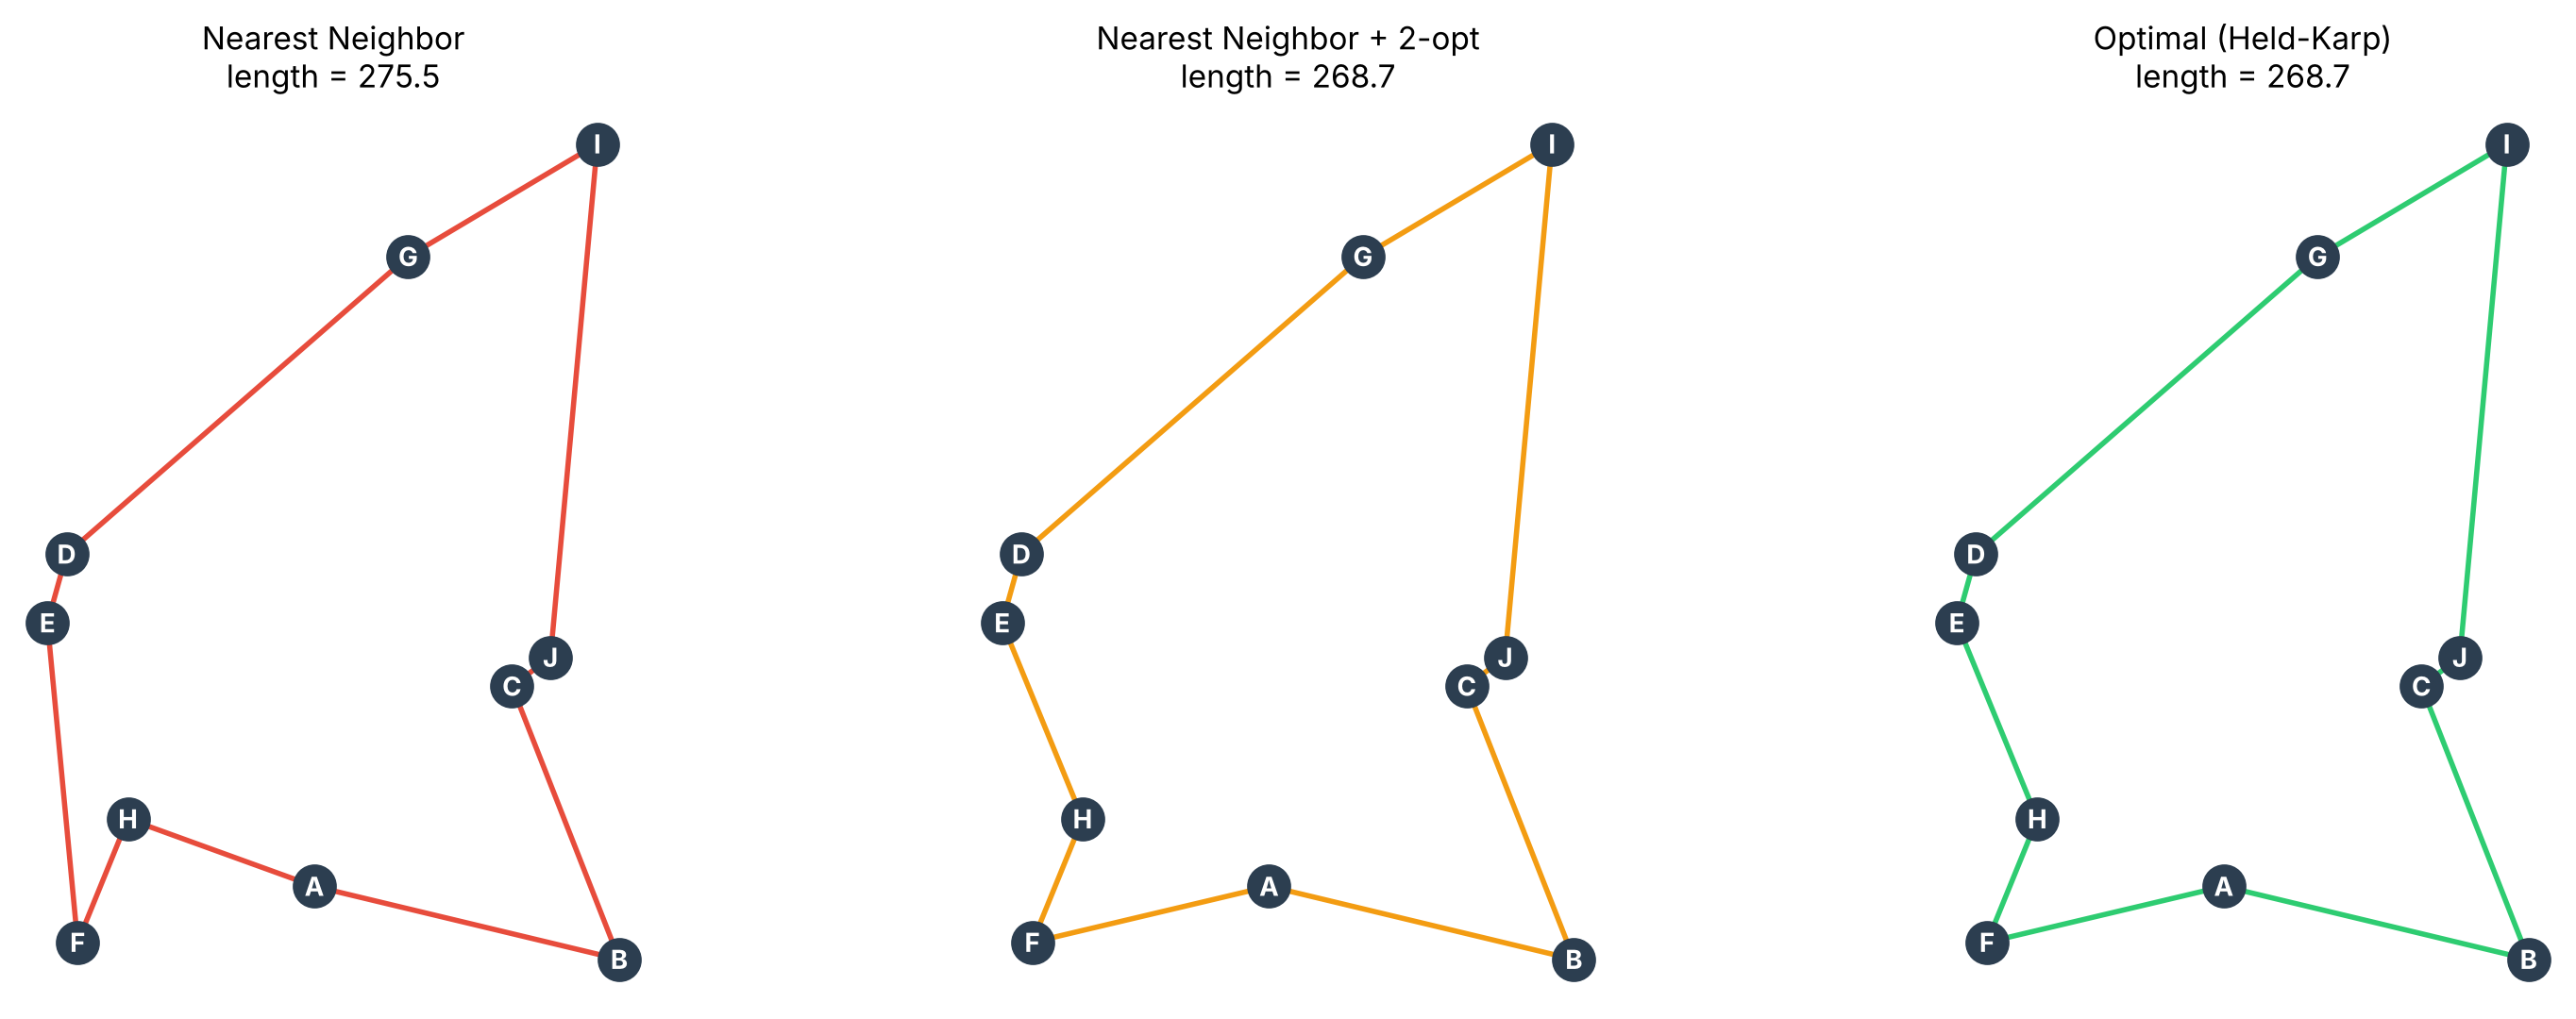

Nearest Neighbor       : 275.55  (2.6% above optimal)
Nearest Neighbor+2-opt : 268.67  (0.0% above optimal)
Optimal (Held-Karp)    : 268.67


In [8]:
random.seed(7)
num_cities = 10
points = [(random.uniform(0, 100), random.uniform(0, 100)) for _ in range(num_cities)]
geo_dist = euclidean_matrix(points)

nn_t, nn_c = tsp_nearest_neighbor(geo_dist)
two_t, two_c = two_opt(geo_dist, nn_t)
opt_t, opt_c = tsp_held_karp(geo_dist)

def draw_tour(ax, tour, cost, title, color):
    closed = tour + [tour[0]]
    xs = [points[c][0] for c in closed]
    ys = [points[c][1] for c in closed]
    ax.plot(xs, ys, '-', color=color, linewidth=2, zorder=1)
    ax.scatter([p[0] for p in points], [p[1] for p in points], s=250, color='#2c3e50', zorder=2)
    for i, (x, y) in enumerate(points):
        ax.text(x, y, city_label(i), color='white', ha='center', va='center', fontweight='bold', zorder=3)
    ax.set_title(f"{title}\nlength = {cost:.1f}")
    ax.set_aspect('equal')
    ax.axis('off')

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
draw_tour(axes[0], nn_t, nn_c, "Nearest Neighbor", '#e74c3c')
draw_tour(axes[1], two_t, two_c, "Nearest Neighbor + 2-opt", '#f39c12')
draw_tour(axes[2], opt_t, opt_c, "Optimal (Held-Karp)", '#2ecc71')
plt.tight_layout()
plt.show()

print(f"Nearest Neighbor       : {nn_c:.2f}  ({100 * (nn_c - opt_c) / opt_c:.1f}% above optimal)")
print(f"Nearest Neighbor+2-opt : {two_c:.2f}  ({100 * (two_c - opt_c) / opt_c:.1f}% above optimal)")
print(f"Optimal (Held-Karp)    : {opt_c:.2f}")


## 5. How Close Do the Heuristics Get? (30 Random Instances)

A single example can be lucky or unlucky. Here we generate **30 random 10-city
instances**, compute the true optimum with Held-Karp, and measure how much
longer each heuristic's tour is (the **optimality gap**).


In [9]:
random.seed(123)
trials = 30
nn_gaps, two_gaps = [], []

for _ in range(trials):
    pts = [(random.uniform(0, 100), random.uniform(0, 100)) for _ in range(10)]
    d = euclidean_matrix(pts)
    _, opt = tsp_held_karp(d)
    _, nn = tsp_nearest_neighbor(d)
    _, two = two_opt(d, tsp_nearest_neighbor(d)[0])
    nn_gaps.append(100 * (nn - opt) / opt)
    two_gaps.append(100 * (two - opt) / opt)

print(f"Over {trials} random 10-city instances (gap = % longer than optimal):\n")
print(f"{'Method':<26}{'Mean gap':<12}{'Worst gap':<12}{'Found optimum':<15}")
print(f"{'Nearest Neighbor':<26}{sum(nn_gaps)/trials:<12.1f}{max(nn_gaps):<12.1f}{sum(g < 1e-9 for g in nn_gaps)}/{trials}")
print(f"{'Nearest Neighbor + 2-opt':<26}{sum(two_gaps)/trials:<12.1f}{max(two_gaps):<12.1f}{sum(g < 1e-9 for g in two_gaps)}/{trials}")


Over 30 random 10-city instances (gap = % longer than optimal):

Method                    Mean gap    Worst gap   Found optimum  
Nearest Neighbor          12.3        32.7        4/30
Nearest Neighbor + 2-opt  0.6         4.7         23/30


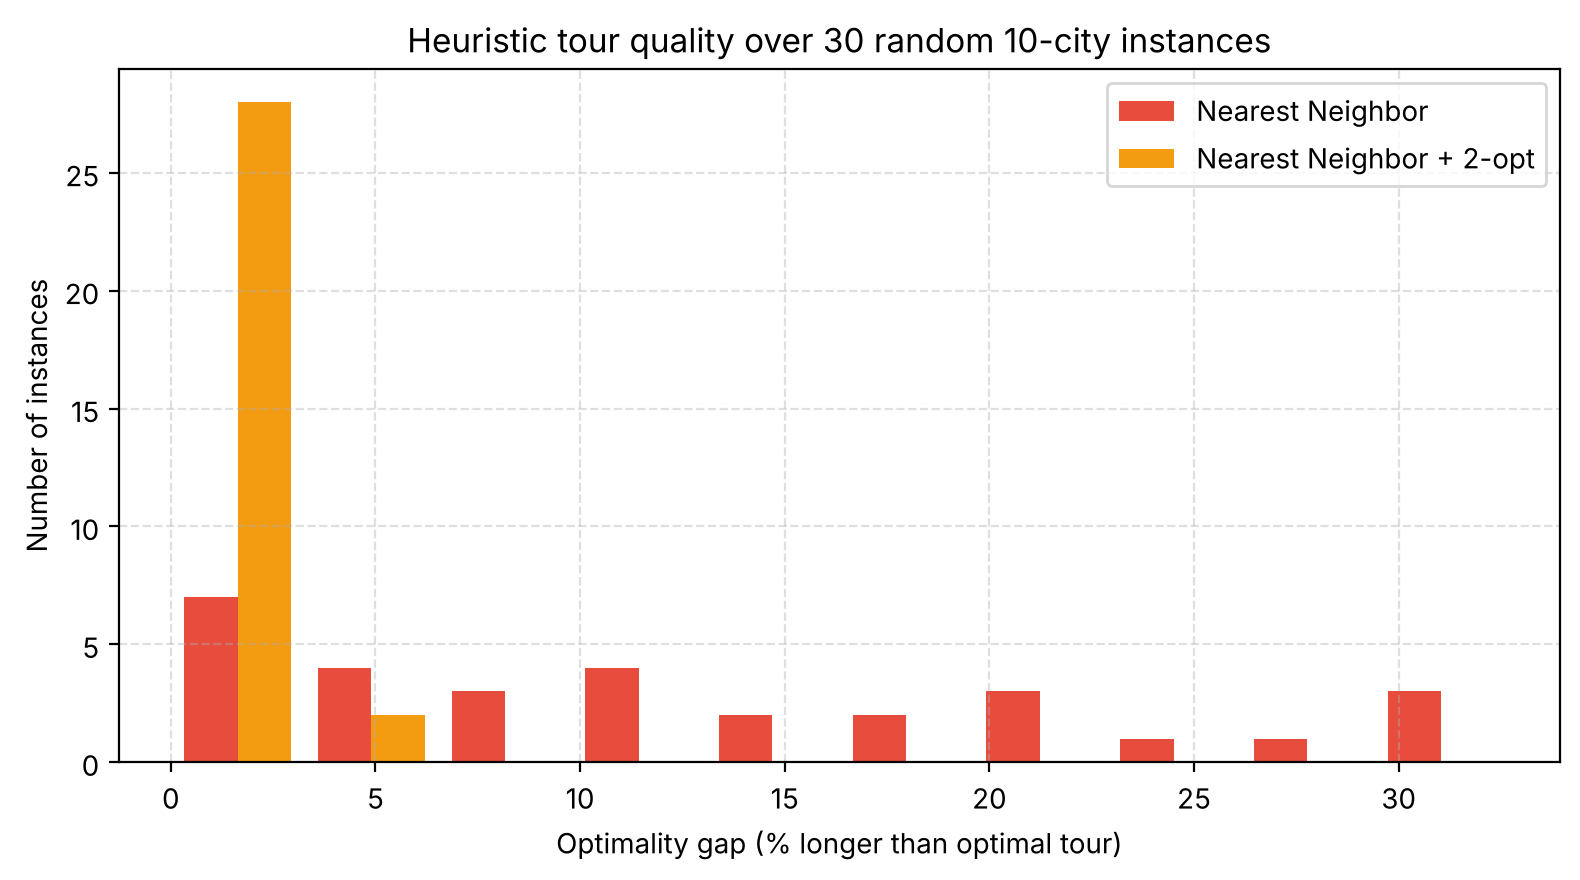

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist([nn_gaps, two_gaps], bins=10, label=['Nearest Neighbor', 'Nearest Neighbor + 2-opt'],
        color=['#e74c3c', '#f39c12'])
ax.set_xlabel("Optimality gap (% longer than optimal tour)")
ax.set_ylabel("Number of instances")
ax.set_title(f"Heuristic tour quality over {trials} random 10-city instances")
ax.legend()
ax.grid(True, ls="--", alpha=0.4)
plt.tight_layout()
plt.show()


## 6. Runtime Comparison as the Number of Cities Grows

All three algorithms run on the **same random instances**. Brute force is only
run up to 10 cities (11 cities would already mean 3.6 million tours; at this
notebook's measured speed, 15 cities - about 87 billion tours - would take more
than a day). Held-Karp goes further, and Nearest Neighbor is effectively
instant throughout. Optimal costs are cross-checked wherever two exact methods
both ran.


In [11]:
random.seed(42)
sizes = list(range(4, 16))
brute_times, hk_times, nn_times = {}, {}, {}

for n in sizes:
    pts = [(random.uniform(0, 100), random.uniform(0, 100)) for _ in range(n)]
    d = euclidean_matrix(pts)

    t0 = time.time(); _, hk_c = tsp_held_karp(d); hk_times[n] = (time.time() - t0) * 1000
    t0 = time.time(); tsp_nearest_neighbor(d);    nn_times[n] = (time.time() - t0) * 1000

    if n <= 10:
        t0 = time.time(); _, bf_c = tsp_brute_force(d); brute_times[n] = (time.time() - t0) * 1000
        assert abs(bf_c - hk_c) < 1e-6, f"Brute force and Held-Karp disagree at n={n}!"

print(f"{'Cities':<9}{'Brute Force (ms)':<20}{'Held-Karp (ms)':<18}{'Nearest Nbr (ms)':<18}")
for n in sizes:
    bf = f"{brute_times[n]:.3f}" if n in brute_times else "(skipped)"
    print(f"{n:<9}{bf:<20}{hk_times[n]:<18.3f}{nn_times[n]:<18.4f}")

print("\n(Brute force and Held-Karp returned identical optimal costs wherever both ran.)")


Cities   Brute Force (ms)    Held-Karp (ms)    Nearest Nbr (ms)  
4        0.014               0.020             0.0136            
5        0.025               0.030             0.0069            
6        0.135               0.065             0.0064            
7        0.760               0.176             0.0083            
8        5.151               0.429             0.0114            
9        42.634              1.058             0.0191            
10       397.152             3.376             0.0279            
11       (skipped)           6.122             0.0329            
12       (skipped)           12.681            0.0339            
13       (skipped)           29.452            0.0429            
14       (skipped)           108.626           0.0541            
15       (skipped)           140.787           0.0527            

(Brute force and Held-Karp returned identical optimal costs wherever both ran.)


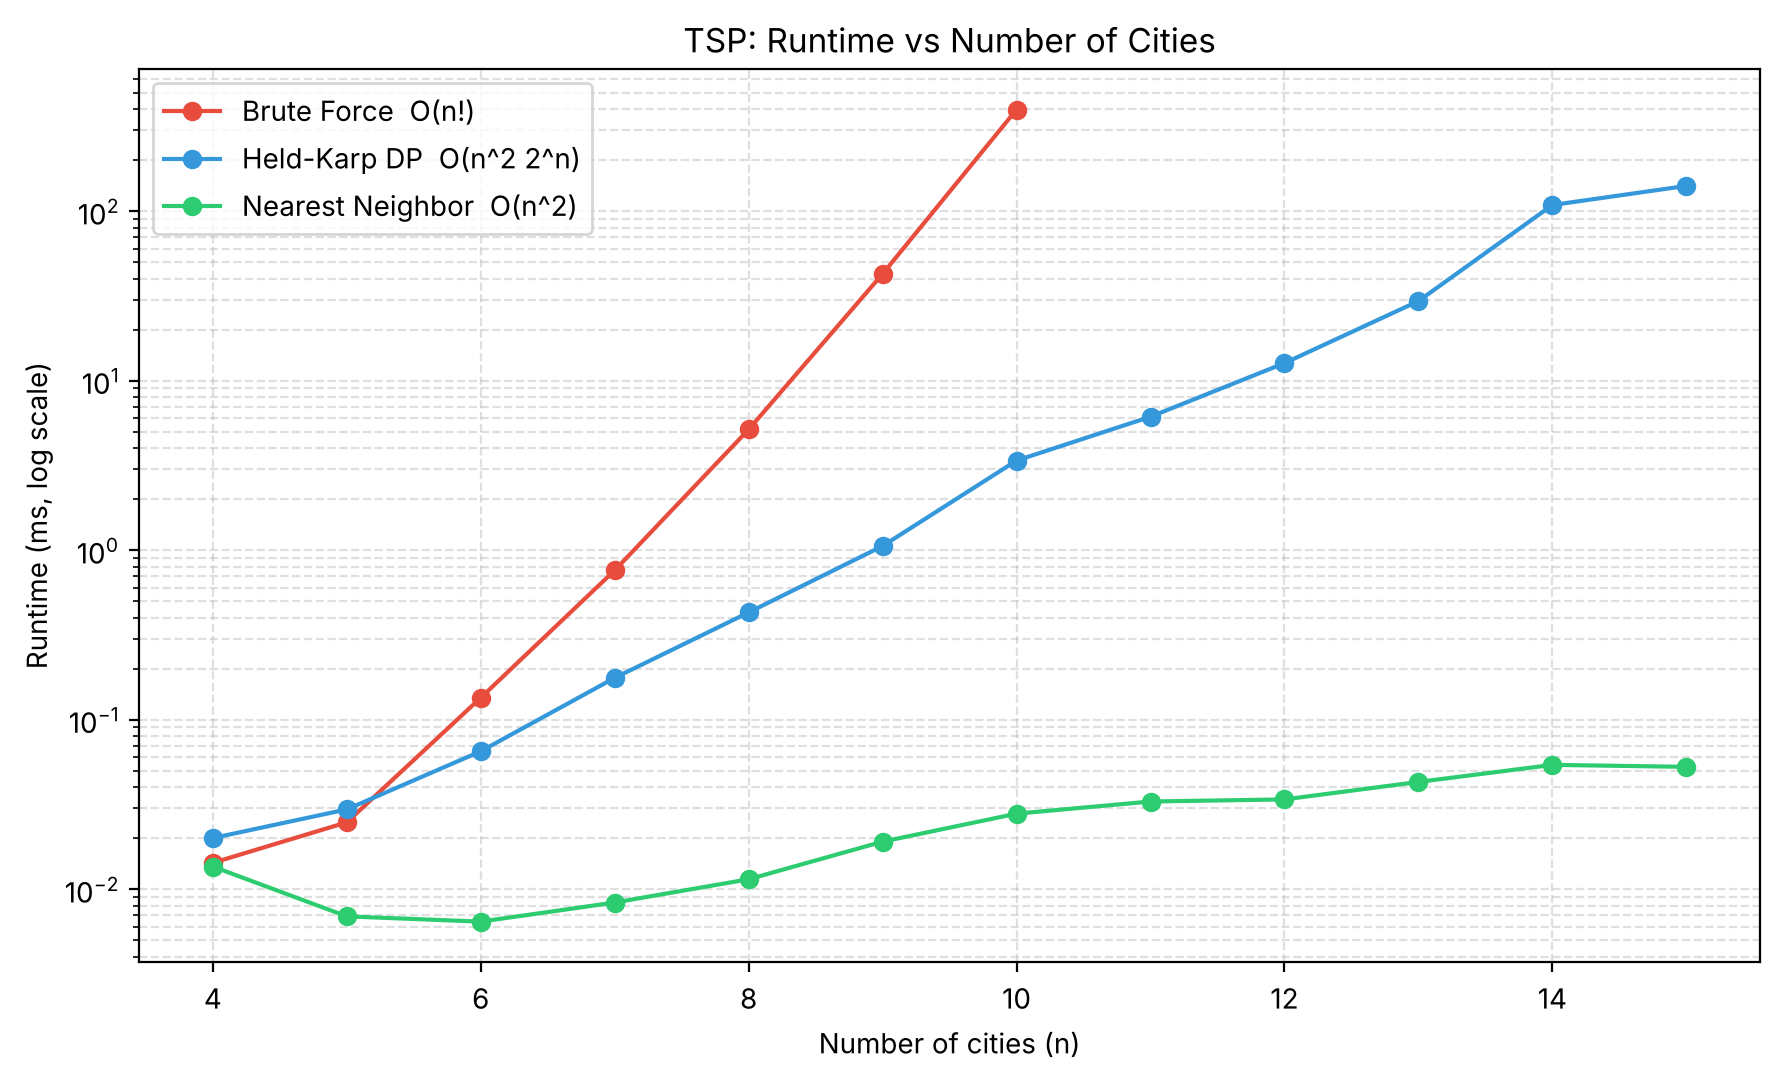

In [12]:
plt.figure(figsize=(9, 5.5))
bf_x = sorted(brute_times)
plt.plot(bf_x, [brute_times[n] for n in bf_x], marker='o', label='Brute Force  O(n!)', color='#e74c3c')
plt.plot(sizes, [hk_times[n] for n in sizes], marker='o', label='Held-Karp DP  O(n^2 2^n)', color='#3498db')
plt.plot(sizes, [nn_times[n] for n in sizes], marker='o', label='Nearest Neighbor  O(n^2)', color='#2ecc71')
plt.yscale('log')
plt.xlabel("Number of cities (n)")
plt.ylabel("Runtime (ms, log scale)")
plt.title("TSP: Runtime vs Number of Cities")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.tight_layout()
plt.show()


## Summary Table

| Algorithm                  | Time Complexity | Space Complexity | Optimal? | Practical Limit (pure Python) |
|------------------------------|-------------------|---------------------|-----------|----------------------------------|
| Brute Force                  | O(n!)             | O(n)                | Yes       | about 10 cities                  |
| Held-Karp (DP)               | O(n^2 * 2^n)      | O(n * 2^n)          | Yes       | about 15-20 cities               |
| Nearest Neighbor             | O(n^2)            | O(n)                | No        | thousands of cities              |
| Nearest Neighbor + 2-opt     | O(n^2) per pass   | O(n)                | No        | hundreds to thousands of cities  |

Where `n` = number of cities.

**Notes:**
- TSP is **NP-hard**: no polynomial-time exact algorithm is known, and one is widely believed not to exist (the famous P vs NP question).
- **Held-Karp** is a textbook example of how dynamic programming can tame a factorial search by remembering the best answer for each *(set of visited cities, current city)* pair. It is still exponential, so it hits a wall (mainly in memory) well before heuristics do.
- Greedy heuristics like **Nearest Neighbor** trade optimality for speed. The experiment above shows how much quality is lost, and that a cheap **2-opt** repair recovers most of it.
- For **metric** instances (distances obey the triangle inequality), **Christofides' algorithm** guarantees a tour at most 1.5x the optimal length. Industrial solvers such as **Concorde** combine branch-and-cut with strong heuristics (e.g., Lin-Kernighan) and have solved instances with tens of thousands of cities exactly.
- Brute force and Held-Karp handle **asymmetric** distances; the 2-opt step as written assumes **symmetric** distances.
- Results here use the *closed tour* version: the salesman must return to the start city.
